In [ ]:
import pandas as pd
import graphviz
import math
import numpy as np
import random
np.random.seed(7) # fix random seed for reproducibility
from keras.models import Sequential
from keras.layers import Dense, Embedding
from keras.layers import LSTM
from matplotlib import pyplot as plt
from keras.preprocessing.text import Tokenizer
from keras.layers import Dropout
from keras.preprocessing.sequence import pad_sequences
from keras.utils.vis_utils import plot_model
import pydotplus as pydot

from graphviz import Digraph
import copy

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving ml_ulstm_predictions.csv to ml_ulstm_predictions.csv


In [ ]:
predictions = pd.read_csv("ml_ulstm_predictions.csv")
#Drop first column. It's irrelevant
headers = list(predictions.columns.values)
predictions = predictions.drop([headers[0]], axis=1)
print(predictions.head())

    0  ... working student machine learning
0 NaN  ...                              0.0
1 NaN  ...                              0.0
2 NaN  ...                              0.0
3 NaN  ...                              0.0
4 NaN  ...                              0.0

[5 rows x 173 columns]


In [ ]:
class helper:
  def __init__(self):
    self.i= 0


  def grabEventsFromHeader(self, header):
    evs = []
    c = 0
    for ev in header:
      if c > 0:
        try:
          num = int(ev)
        except:
          evs.append(ev)
      c = c + 1
    return evs
  def rowIsFirst(self, row, activities, headers):
    foundValues = []
    for i in range(0,len(headers)):
      val = headers[i]
      if row[val] in activities:
        foundValues.append(row[val])
    if (len(foundValues) == 0):
      return True
    return False

  def rowIsLast(self, row, evName):
    rowEv = row.idxmax()
    try:
      if rowEv.lower() == evName.lower():
        return True
    except:
      return False
    return False

  def divideMatrix(self, matrix):
    headers = list(matrix.columns.values)
    leftHeaders = []
    rightHeaders = []
    for i in range(0,len(headers)):
      ev = headers[i]
      try:
          num = int(ev)
          leftHeaders.append(ev)
      except:
          rightHeaders.append(ev)
    leftData = matrix[leftHeaders]
    rightData = matrix[rightHeaders]
    return [leftData, rightData]



In [ ]:
class resultGraphing:
  def __init__(self):
    self.i= 0


  def decomposeResultProb(self, results):
    helper_ = helper()
    headers = list(results.columns.values)
    events = helper_.grabEventsFromHeader(headers)
    matrices = []
    matricesLeft = []
    lastIndex = 0
    totalBegin = 0
    ind = 0
    newMatrix = helper_.divideMatrix(results)
    for index, row in newMatrix[1].iterrows():
      ind = index
      rowIsLast = helper_.rowIsLast(row, "end")
      if rowIsLast:
        sequenceList = newMatrix[1].iloc[lastIndex:index+1, :]
        sequenceListLeft = newMatrix[0].iloc[lastIndex:index+1, :]
        matrices.append(sequenceList)
        matricesLeft.append(sequenceListLeft)
        lastIndex = index + 1
    return matrices, matricesLeft

  def rowIsAnewSequence(self, row):
    try:
      return math.isnan(row["1"])
    except:
      return False

  def linkAndProbabilities(self, matrices, count = 0):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    for i in range(0,len(matrices)):
      thisMatrix = matrices[i]
      lastEvent = "Start";
      sequence = []
      for index, row in thisMatrix.iterrows():
        row = pd.to_numeric(row)
        #print(row) # prints the rows
        evName = row.idxmax(axis=1) # picks event with the highest probability
        link = lastEvent + "<-->" + evName
        sequence.append(evName)
        if link not in links:
          if lastEvent != evName:
            links.append(link)
            prob = row[evName] #g
            probabilities.append(prob)
        lastEvent = evName
      # The Last element is End and undesirable
      sequence.pop()
      sequences.append(sequence)
    return links, probabilities, sequences



  def drawGraph(self, transitions, probabilities, counter = 0):
    G = Digraph('process_model', filename='graph_'+str(counter)+'.gv')
    G.attr(rankdir='LR', size='7,5')
    G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
    G.node('Start')
    G.node('END')
    G.attr('node', shape='box', style="bold")
    for i in range(0,len(transitions)):
      G.attr('edge', style="bold", penwidth='3.0', label=str(probabilities[i]))
      fromto = transitions[i].split("<-->")
      G.edge(fromto[0], fromto[1])
    G.view()
    return G

###with threshold
  # def drawGraph(self, transitions, probabilities, threshold, counter = 0):

  #   G = Digraph('process_model', filename='Graph_'+str(counter)+'.gv')
  #   G.attr(rankdir='LR', size='7,5')
  #   G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
  #   G.node('Start')
  #   G.node('END')
  #   G.attr('node', shape='box', style="bold")
  #   for i in range(0,len(transitions)):
  #     fromto = transitions[i].split("<-->")
  #     if (fromto[0].lower() != "end"):
  #       # Here Limit or Prune using the threshold
  #       if probabilities[i] > (threshold*100) or fromto[0].lower() == "start": # This ignores probabilty less than threshold
  #         G.attr('edge', style="bold", penwidth='3.0', label=str(probabilities[i]))
  #         fromto = transitions[i].split("<-->")
  #         G.edge(fromto[0], fromto[1])
  #   G.view()
  #   return G


In [ ]:
resultGraphing_ = resultGraphing()

probs, seqs = resultGraphing_.decomposeResultProb(predictions)
link_i, probabilities_i, sequences_i = resultGraphing_.linkAndProbabilities(probs)
Graph = resultGraphing_.drawGraph(link_i, probabilities_i)

print(len(sequences_i))
print(sequences_i)

56
[['senior machine learning engineer', 'machine learning engineer', 'software engineer', 'machine learning intern', 'machine learning intern', 'senior machine learning engineer', 'machine learning engineer', 'software engineer', 'software engineer', 'machine learning intern'], [], [], [], ['senior machine learning engineer', 'data scientist', 'machine learning engineer', 'machine learning engineer', 'senior software engineer', 'research assistant', 'senior machine learning engineer', 'machine learning engineer', 'researcher', 'software engineer', 'software engineer'], ['senior machine learning engineer', 'machine learning engineer', 'software engineer', 'machine learning engineer', 'software engineer', 'software engineer'], [], [], [], [], [], ['senior machine learning engineer', 'senior machine learning engineer', 'software engineer', 'research assistant', 'data scientist'], [], ['senior machine learning engineer', 'data scientist', 'software engineer', 'data scientist', 'senior mac

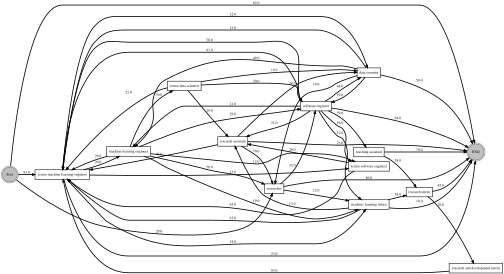

In [ ]:
Graph